Imports and configuration

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# CONFIGURATION

DATA_PATH = "data/processed/paddy_cleaned.csv"
TRAIN_DATA_PATH = "data/processed/train_data.csv"

OUTPUT_DIR = "experiments/hybrid"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Production 000 Mt."

ARIMA_ORDER = (1, 1, 1)

MIN_ARIMA_HISTORY = 12
RESIDUAL_LAGS = 3

RF_PARAMETERS = {
    "n_estimators": 100,
    "max_depth": 3,
    "min_samples_leaf": 2,
    "max_features": 1.0,
    "random_state": 42,
    "n_jobs": -1
}

Data loading

In [2]:
def load_data():

    data = pd.read_csv(DATA_PATH)

    data["Year"] = pd.to_numeric(data["Year"]).astype(int)
    data[TARGET] = pd.to_numeric(data[TARGET]).astype(float)

    return data.sort_values("Year").reset_index(drop=True)


def get_split_year():

    train_data = pd.read_csv(TRAIN_DATA_PATH)

    return int(train_data["Year"].max())


data = load_data()

print("Dataset loaded:", data.shape)
print("Historical period:", data["Year"].min(), "-", data["Year"].max())
print("Training split year:", get_split_year())

display(data.head())

Dataset loaded: (61, 2)
Historical period: 1952 - 2012
Training split year: 2000


,Year,Production 000 Mt.
0,1952,604.0
1,1953,458.0
2,1954,650.0
3,1955,747.0
4,1956,574.0


ARIMA forecasting

In [3]:
def arima_predict(history):

    values = history[TARGET].astype(float).values

    model = ARIMA(
        values,
        order=ARIMA_ORDER
    )

    fitted_model = model.fit()

    prediction = fitted_model.forecast(steps=1)

    return float(prediction[0])

Generate chronological out-of-sample residuals

In [4]:
def generate_oos_residuals(history):

    values = history[TARGET].astype(float).values

    residuals = []

    # Each residual is generated by forecasting an unseen
    # observation using only the observations before it.

    for i in range(MIN_ARIMA_HISTORY, len(values)):

        previous_values = values[:i]

        temporary_history = pd.DataFrame({
            TARGET: previous_values
        })

        prediction = arima_predict(temporary_history)

        actual = float(values[i])

        residual = actual - prediction

        residuals.append(residual)

    return np.array(residuals, dtype=float)

Residual feature engineering

In [5]:
def create_residual_training_data(residuals):

    X = []
    y = []

    for i in range(RESIDUAL_LAGS, len(residuals)):

        X.append([
            residuals[i - 1],
            residuals[i - 2],
            residuals[i - 3]
        ])

        y.append(residuals[i])

    return np.array(X), np.array(y)

Train the residual Random Forest model

In [6]:
def train_residual_model(history):

    residuals = generate_oos_residuals(history)

    if len(residuals) <= RESIDUAL_LAGS:
        return None, residuals

    X, y = create_residual_training_data(residuals)

    model = RandomForestRegressor(**RF_PARAMETERS)

    model.fit(X, y)

    return model, residuals

Predict residual correction

In [7]:
def predict_residual_correction(model, residuals):

    if model is None or len(residuals) < RESIDUAL_LAGS:
        return 0.0

    features = np.array([[
        residuals[-1],
        residuals[-2],
        residuals[-3]
    ]])

    return float(model.predict(features)[0])

Hybrid one-step forecast

In [8]:
def hybrid_predict(history):

    arima_forecast = arima_predict(history)

    residual_model, residuals = train_residual_model(history)

    residual_correction = predict_residual_correction(
        residual_model,
        residuals
    )

    hybrid_forecast = arima_forecast + residual_correction

    return {
        "ARIMA": arima_forecast,
        "Residual_Correction": residual_correction,
        "Hybrid": hybrid_forecast,
        "Residual_Model": residual_model,
        "Residuals": residuals
    }

Evaluation metrics

In [9]:
def calculate_metrics(actual, predicted):

    actual = np.array(actual, dtype=float)
    predicted = np.array(predicted, dtype=float)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

Experiment A: Walk-forward evaluation

In [10]:
def walk_forward_evaluation(data):

    split_year = get_split_year()

    history = data[data["Year"] <= split_year].copy()
    test_data = data[data["Year"] > split_year].copy()

    predictions = []

    for _, row in test_data.iterrows():

        year = int(row["Year"])

        result = hybrid_predict(history)

        predictions.append({
            "Year": year,
            "Actual": float(row[TARGET]),
            "ARIMA_Predicted": result["ARIMA"],
            "Residual_Correction": result["Residual_Correction"],
            "Hybrid_Predicted": result["Hybrid"]
        })

        # Add actual production only after prediction
        new_row = pd.DataFrame([{
            "Year": year,
            TARGET: float(row[TARGET])
        }])

        history = pd.concat(
            [history, new_row],
            ignore_index=True
        )

    results = pd.DataFrame(predictions)

    results.to_csv(
        f"{OUTPUT_DIR}/walk_forward_predictions.csv",
        index=False
    )

    metrics = calculate_metrics(
        results["Actual"],
        results["Hybrid_Predicted"]
    )

    print("\n========== HYBRID WALK-FORWARD ==========")

    for name, value in metrics.items():
        print(f"{name}: {value:.2f}")

    return results, metrics


walk_results, walk_metrics = walk_forward_evaluation(data)
display(walk_results)


========== HYBRID WALK-FORWARD ==========
MAE: 304.47
RMSE: 359.12
MAPE: 8.85


,Year,Actual,ARIMA_Predicted,Residual_Correction,Hybrid_Predicted
0,2001,2695.0,2818.308445,137.350706,2955.659151
1,2002,2860.0,2722.053162,177.502756,2899.555917
2,2003,3067.0,2823.906697,47.235708,2871.142405
3,2004,2628.0,2992.969325,-30.426167,2962.543158
4,2005,3246.0,2731.364338,-47.902968,2683.461370
5,2006,3341.0,3059.286689,-14.270624,3045.016065
6,2007,3131.0,3245.505060,-11.133013,3234.372047
7,2008,3875.0,3162.507525,144.839876,3307.347401
8,2009,3652.0,3614.775789,103.737689,3718.513478
9,2010,4301.0,3659.302929,12.809404,3672.112333


Experiment B: Fixed-origin recursive forecast

In [11]:
def recursive_hybrid_forecast(history, future_years):

    history = history.copy()

    residual_model, residuals = train_residual_model(history)

    predictions = []

    for year in future_years:

        arima_forecast = arima_predict(history)

        correction = predict_residual_correction(
            residual_model,
            residuals
        )

        hybrid_forecast = arima_forecast + correction

        predictions.append({
            "Year": int(year),
            "ARIMA_Predicted": arima_forecast,
            "Residual_Correction": correction,
            "Hybrid_Predicted": hybrid_forecast
        })

        # Use predicted production for recursive forecasting
        new_row = pd.DataFrame([{
            "Year": int(year),
            TARGET: hybrid_forecast
        }])

        history = pd.concat(
            [history, new_row],
            ignore_index=True
        )

        # Future residuals are unknown.
        # Feed the predicted correction into the residual history.
        residuals = np.append(residuals, correction)

    return pd.DataFrame(predictions)


def fixed_origin_evaluation(data):

    split_year = get_split_year()

    history = data[data["Year"] <= split_year].copy()
    test_data = data[data["Year"] > split_year].copy()

    predictions = recursive_hybrid_forecast(
        history,
        test_data["Year"].tolist()
    )

    results = predictions.merge(
        test_data[["Year", TARGET]],
        on="Year"
    )

    results = results.rename(
        columns={TARGET: "Actual"}
    )

    results.to_csv(
        f"{OUTPUT_DIR}/fixed_origin_predictions.csv",
        index=False
    )

    metrics = calculate_metrics(
        results["Actual"],
        results["Hybrid_Predicted"]
    )

    print("\n========== HYBRID FIXED-ORIGIN ==========")

    for name, value in metrics.items():
        print(f"{name}: {value:.2f}")

    return results, metrics


fixed_results, fixed_metrics = fixed_origin_evaluation(data)
display(fixed_results)


========== HYBRID FIXED-ORIGIN ==========
MAE: 276.11
RMSE: 350.49
MAPE: 7.97


,Year,ARIMA_Predicted,Residual_Correction,Hybrid_Predicted,Actual
0,2001,2818.308445,137.350706,2955.659151,2695.0
1,2002,2915.071089,33.836132,2948.907221,2860.0
2,2003,2935.756974,91.847850,3027.604823,3067.0
3,2004,3001.417362,114.602951,3116.020314,2628.0
4,2005,3082.820091,70.155514,3152.975605,3246.0
5,2006,3131.658063,100.960626,3232.618689,3341.0
6,2007,3204.331113,87.881394,3292.212506,3131.0
7,2008,3267.328694,94.240706,3361.569400,3875.0
8,2009,3335.656496,100.707253,3436.363749,3652.0
9,2010,3409.200367,84.748170,3493.948537,4301.0


Ten-year future forecast

In [12]:
def future_forecast(data):

    future_years = range(
        int(data["Year"].max()) + 1,
        int(data["Year"].max()) + 11
    )

    forecast = recursive_hybrid_forecast(
        data,
        future_years
    )

    forecast.to_csv(
        f"{OUTPUT_DIR}/future_forecast.csv",
        index=False
    )

    print("\n========== HYBRID FUTURE FORECAST ==========")
    print(forecast.to_string(index=False))

    return forecast


future_results = future_forecast(data)
display(future_results)


========== HYBRID FUTURE FORECAST ==========
 Year  ARIMA_Predicted  Residual_Correction  Hybrid_Predicted
 2013      3882.514651           205.580844       4088.095495
 2014      4000.801864            25.618405       4026.420269
 2015      4035.329216           134.310846       4169.640061
 2016      4115.838684            16.724187       4132.562872
 2017      4138.262491            71.332776       4209.595267
 2018      4180.777381           175.396162       4356.173543
 2019      4295.598320           -96.078310       4199.520010
 2020      4250.375043           143.044225       4393.419269
 2021      4325.552801            87.134761       4412.687562
 2022      4394.919287            79.241202       4474.160488


,Year,ARIMA_Predicted,Residual_Correction,Hybrid_Predicted
0,2013,3882.514651,205.580844,4088.095495
1,2014,4000.801864,25.618405,4026.420269
2,2015,4035.329216,134.310846,4169.640061
3,2016,4115.838684,16.724187,4132.562872
4,2017,4138.262491,71.332776,4209.595267
5,2018,4180.777381,175.396162,4356.173543
6,2019,4295.598320,-96.078310,4199.520010
7,2020,4250.375043,143.044225,4393.419269
8,2021,4325.552801,87.134761,4412.687562
9,2022,4394.919287,79.241202,4474.160488


Actual vs. predicted visualization

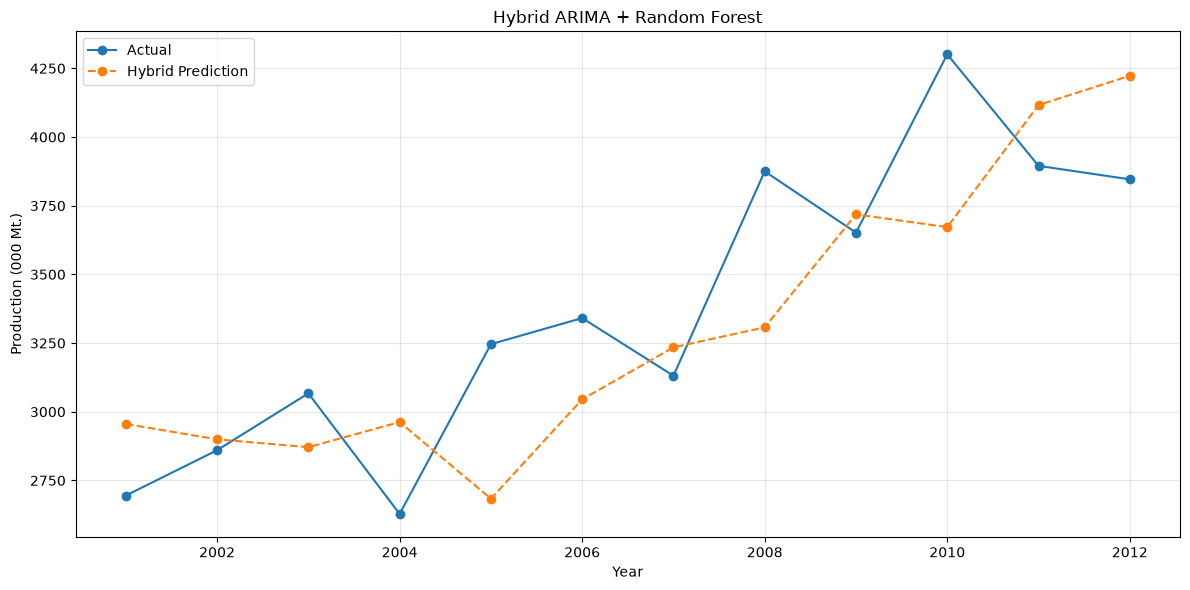

In [13]:
def plot_predictions(results):

    plt.figure(figsize=(12, 6))

    plt.plot(
        results["Year"],
        results["Actual"],
        marker="o",
        label="Actual"
    )

    plt.plot(
        results["Year"],
        results["Hybrid_Predicted"],
        marker="o",
        linestyle="--",
        label="Hybrid Prediction"
    )

    plt.title("Hybrid ARIMA + Random Forest")
    plt.xlabel("Year")
    plt.ylabel("Production (000 Mt.)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/actual_vs_predicted.png",
        dpi=300
    )

    plt.show()
    plt.close()


plot_predictions(walk_results)